In [10]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(42)
jam = rng.uniform(1, 9, size=60)
nilai = 35 + 5 * jam + rng.normal(
    loc=0, scale=6, size=60
)
df = pd.DataFrame({"jam_belajar": jam, "nilai_ujian": nilai})

In [11]:
df.head()

,jam_belajar,nilai_ujian
0,7.191648,65.763255
1,4.511028,63.364808
2,7.868783,64.246698
3,6.578944,65.885411
4,1.753419,44.743612


In [12]:
df.shape

(60, 2)

In [13]:
df.isna().sum()

,0
jam_belajar,0
nilai_ujian,0


In [14]:
df.describe()

,jam_belajar,nilai_ujian
count,60.000000,60.000000
mean,5.158475,59.549841
std,2.268995,12.131672
min,1.058898,29.930568
25%,3.184446,50.334266
50%,5.121159,60.134906
75%,7.200503,67.910802
max,8.804979,82.542228


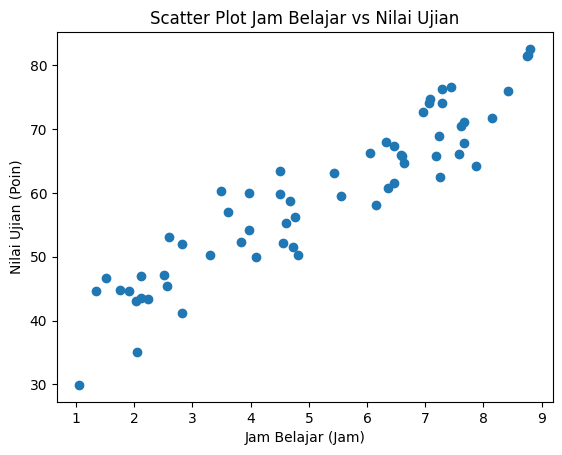

In [16]:
import matplotlib.pyplot as plt
plt.scatter(df["jam_belajar"], df["nilai_ujian"])
plt.xlabel("Jam Belajar (Jam)")
plt.ylabel("Nilai Ujian (Poin)")
plt.title("Scatter Plot Jam Belajar vs Nilai Ujian")
plt.show()

In [18]:
from sklearn.model_selection import train_test_split
X = df[['jam_belajar']]
y = df['nilai_ujian']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)


In [21]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [23]:
b0 = float(model.intercept_)
b1 = float(model.coef_[0])
print(f"Model colab : nilai prediksi = "
f"{b0:.3f} + ({b1:.3f}) x jam_belajar")

Model colab : nilai prediksi = 34.841 + (4.839) x jam_belajar


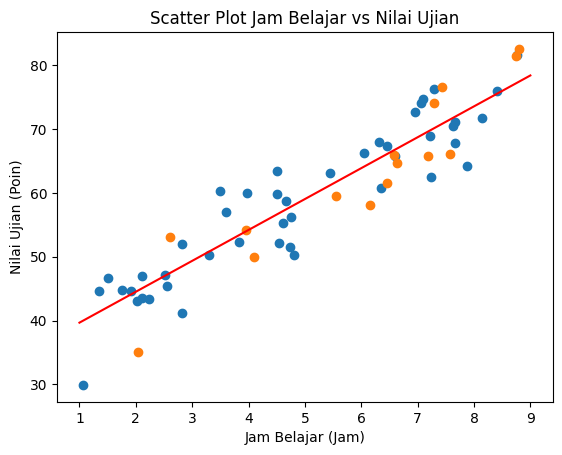

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

x_grid = pd.DataFrame(
    {"jam_belajar" : np.linspace(1,9,100)})
y_grid = model.predict(x_grid)

plt.scatter(X_train['jam_belajar'], y_train, label='Train Data')
plt.scatter(X_test["jam_belajar"], y_test, label='Test Data')
plt.xlabel("Jam Belajar (Jam)")
plt.ylabel("Nilai Ujian (Poin)")
plt.title("Scatter Plot Jam Belajar vs Nilai Ujian")
plt.plot(x_grid["jam_belajar"], y_grid, color='red', label='Regression Line')


In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pred_test = model.predict(X_test)
mae = mean_absolute_error(y_test,pred_test)
rmse = np.sqrt(mean_squared_error(y_test,pred_test))
r2 = r2_score(y_test,pred_test)
print("mae :", mae)
print("rmse :", rmse)
print("r2 :", r2)

mae : 4.323764956409487
rmse : 4.884253621661415
r2 : 0.8388802621811073
